# Narrative Analysis

Chicago Traffic Crash Analytics, Checkpoint 5

Builds on `eda.ipynb`. Produces every number and figure used in the README's
"Main Findings" section. Same code as `scripts/narrative_analysis.py`.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
import statsmodels.formula.api as smf

plt.rcParams["figure.figsize"] = (7, 4.5)
FIGDIR = "../figures"

crashes = pd.read_parquet("../data/raw/crashes.parquet")
crashes["injured"] = (pd.to_numeric(crashes["injuries_total"], errors="coerce").fillna(0) > 0).astype(int)
crashes["crash_hour_num"] = pd.to_numeric(crashes["crash_hour"], errors="coerce")
crashes["speed_num"] = pd.to_numeric(crashes["posted_speed_limit"], errors="coerce")


## Finding 1: overnight vs midday injury rate

In [2]:
overnight = crashes[crashes["crash_hour_num"].isin([22, 23, 0, 1, 2, 3])]
midday = crashes[crashes["crash_hour_num"].isin([10, 11, 12, 13])]

n1, n2 = overnight["injured"].sum(), midday["injured"].sum()
N1, N2 = len(overnight), len(midday)
rate1, rate2 = n1 / N1, n2 / N2

stat, pval = proportions_ztest([n1, n2], [N1, N2])
ci1 = proportion_confint(n1, N1, method="wilson")
ci2 = proportion_confint(n2, N2, method="wilson")

print(f"overnight: n={N1}, rate={rate1:.4f}, CI={ci1}")
print(f"midday: n={N2}, rate={rate2:.4f}, CI={ci2}")
print(f"z={stat:.2f}, p={pval:.2e}")


overnight: n=28925, rate=0.1867, CI=(0.1822408725922385, 0.19122176586840037)
midday: n=46449, rate=0.1382, CI=(0.1350860734946877, 0.1413629241453097)
z=17.81, p=6.34e-71


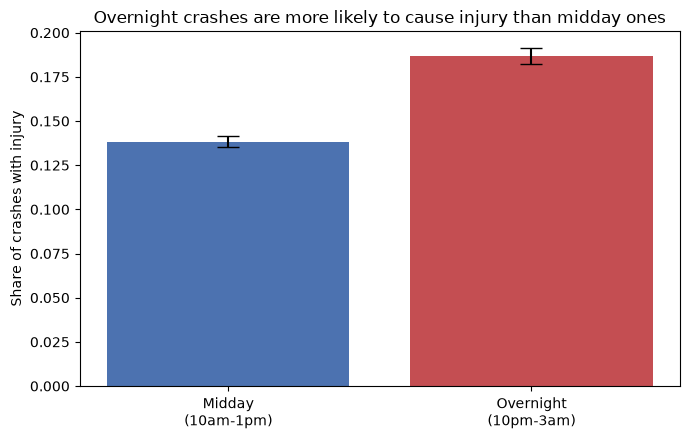

In [3]:
fig, ax = plt.subplots()
ax.bar(["Midday\n(10am-1pm)", "Overnight\n(10pm-3am)"], [rate2, rate1],
       yerr=[[rate2 - ci2[0], rate1 - ci1[0]], [ci2[1] - rate2, ci1[1] - rate1]],
       capsize=8, color=["#4c72b0", "#c44e52"])
ax.set_ylabel("Share of crashes with injury")
ax.set_title("Overnight crashes are more likely to cause injury than midday ones")
plt.tight_layout()
plt.savefig(f"{FIGDIR}/finding-1-overnight-vs-midday.png", dpi=150)
plt.show()


## Finding 2: weather effect, baseline vs full logistic regression

In [4]:
model_df = crashes.copy()
model_df["hour_bucket"] = pd.cut(
    model_df["crash_hour_num"],
    bins=[-1, 5, 9, 15, 19, 23],
    labels=["overnight", "morning", "midday", "evening_rush", "night"],
)
model_df["is_bad_weather"] = model_df["weather_condition"].isin(
    ["RAIN", "SNOW", "FOG/SMOKE/HAZE", "SLEET/HAIL", "BLOWING SNOW",
     "FREEZING RAIN/DRIZZLE", "BLOWING SAND, SOIL, DIRT"]
)
model_df = model_df.dropna(subset=["hour_bucket", "speed_num", "lighting_condition",
                                     "roadway_surface_cond", "road_defect"])
model_df = model_df[(model_df["speed_num"] > 0) & (model_df["speed_num"] <= 70)]

baseline = smf.logit("injured ~ is_bad_weather + C(hour_bucket)", data=model_df).fit(disp=0)
full = smf.logit(
    "injured ~ is_bad_weather + C(hour_bucket) + C(lighting_condition) + "
    "C(roadway_surface_cond) + C(road_defect) + speed_num",
    data=model_df,
).fit(disp=0)

base_or = np.exp(baseline.params["is_bad_weather[T.True]"])
base_p = baseline.pvalues["is_bad_weather[T.True]"]
full_or = np.exp(full.params["is_bad_weather[T.True]"])
full_p = full.pvalues["is_bad_weather[T.True]"]

print(f"baseline OR={base_or:.3f}, p={base_p:.2e}")
print(f"full OR={full_or:.3f}, p={full_p:.2e}")
print(f"n={len(model_df)}")


baseline OR=1.257, p=2.23e-40
full OR=1.049, p=1.20e-01
n=222447


In [5]:
# check: is weather basically the same signal as road surface condition?
pd.crosstab(model_df["is_bad_weather"], model_df["roadway_surface_cond"], normalize="index").round(3)


roadway_surface_cond,DRY,ICE,OTHER,"SAND, MUD, DIRT",SNOW OR SLUSH,UNKNOWN,WET
is_bad_weather,,,,,,,
False,0.81,0.002,0.003,0.0,0.004,0.145,0.036
True,0.03,0.014,0.001,0.0,0.104,0.021,0.831


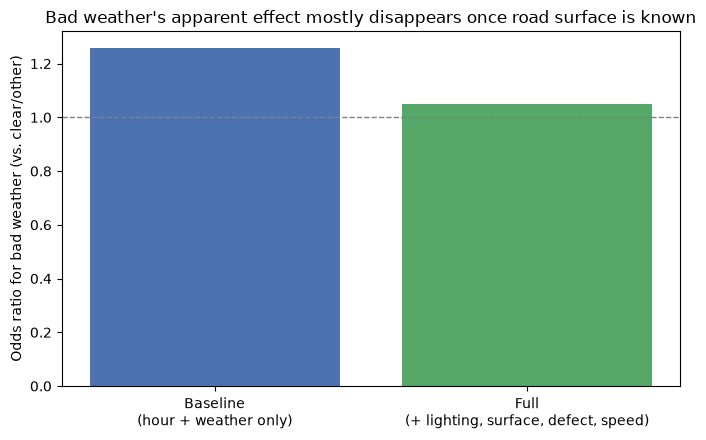

In [6]:
fig, ax = plt.subplots()
ax.bar(["Baseline\n(hour + weather only)", "Full\n(+ lighting, surface, defect, speed)"],
       [base_or, full_or], color=["#4c72b0", "#55a868"])
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1)
ax.set_ylabel("Odds ratio for bad weather (vs. clear/other)")
ax.set_title("Bad weather's apparent effect mostly disappears once road surface is known")
plt.tight_layout()
plt.savefig(f"{FIGDIR}/finding-2-weather-odds-ratio.png", dpi=150)
plt.show()


## Finding 3: snow surprise

In [7]:
for cond in ["CLEAR", "RAIN", "SNOW"]:
    sub = crashes[crashes["weather_condition"] == cond]
    n, N = sub["injured"].sum(), len(sub)
    ci = proportion_confint(n, N, method="wilson")
    print(f"{cond}: n={N}, rate={n/N:.4f}, CI={ci}")

print()
print(crashes[crashes["weather_condition"].isin(["CLEAR", "RAIN", "SNOW"])]
      .groupby("weather_condition")["speed_num"].mean().round(2))

snow = crashes[crashes["weather_condition"] == "SNOW"]
clear = crashes[crashes["weather_condition"] == "CLEAR"]
stat2, pval2 = proportions_ztest([snow["injured"].sum(), clear["injured"].sum()], [len(snow), len(clear)])
print(f"snow vs clear: z={stat2:.2f}, p={pval2:.2e}")


CLEAR: n=171691, rate=0.1640, CI=(0.16225998472723355, 0.1657629248738592)
RAIN: n=19948, rate=0.1989, CI=(0.1934358496056557, 0.20451445865075327)
SNOW: n=4251, rate=0.1440, CI=(0.1337343827834985, 0.15484075466968708)



weather_condition
CLEAR    28.56
RAIN     29.18
SNOW     28.81
Name: speed_num, dtype: float64
snow vs clear: z=-3.49, p=4.84e-04


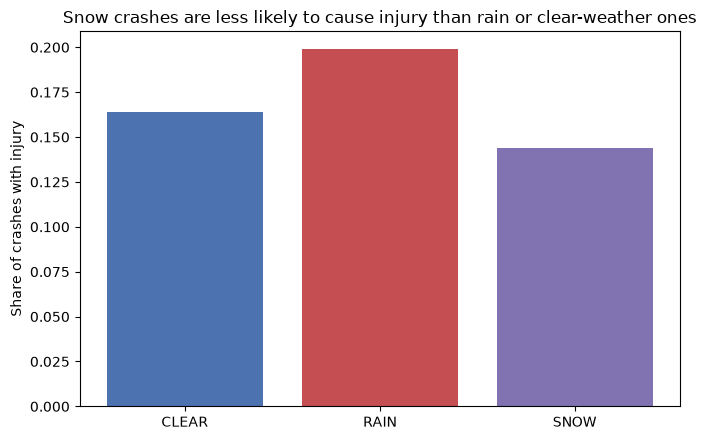

In [8]:
rates = crashes[crashes["weather_condition"].isin(["CLEAR", "RAIN", "SNOW"])].groupby("weather_condition")["injured"].mean()
rates = rates.reindex(["CLEAR", "RAIN", "SNOW"])
fig, ax = plt.subplots()
ax.bar(rates.index, rates.values, color=["#4c72b0", "#c44e52", "#8172b2"])
ax.set_ylabel("Share of crashes with injury")
ax.set_title("Snow crashes are less likely to cause injury than rain or clear-weather ones")
plt.tight_layout()
plt.savefig(f"{FIGDIR}/finding-3-snow-surprise.png", dpi=150)
plt.show()
